# Capítulo 3 · Actividad: limpieza de datos y outliers

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/riosinda/ml-course/blob/main/notebooks/exercises/chapter_03/02_actividad_limpieza_outliers.ipynb)

Vas a aplicar lo que viste en la notebook de clase `04_limpieza_y_outliers` a **tres datasets distintos**. Cada uno tiene problemas diferentes, igual que en la vida real.

### Antes de empezar

1. **Copia esta notebook a `workspace/`** y trabaja sobre la copia.
2. Si todavía no tienes los datos, descárgalos desde la raíz del repo:
   ```bash
   uv run python scripts/download_data.py
   ```

### Cómo trabajar

- Cada ejercicio tiene una celda `# Tu código aquí`. Añade todas las celdas que necesites.
- En las celdas ✍️ **justifica tus decisiones**: en limpieza de datos casi nunca hay una única respuesta correcta, pero siempre tiene que haber un motivo.
- Al terminar, ejecuta **Kernel → Restart & Run All**.

| Parte | Datos | Tema |
|---|---|---|
| A. Empleados | una tabla pequeña creada en la notebook | Limpieza estructural e imputación |
| B. Pingüinos | `data/penguins.csv` | Valores faltantes |
| C. Viviendas de California | `data/california_housing.csv` | Outliers |

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.impute import SimpleImputer

# Carpeta data/ en la raíz del repo: subimos de carpeta en carpeta hasta dar con pyproject.toml
raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), Path.cwd())
DATA_DIR = raiz / "data"

---
## Parte A · Empleados 👩‍💼

Recursos Humanos te pasa esta tabla, exportada a mano de varias hojas de cálculo. Ejecuta la celda para crearla.

In [2]:
empleados = pd.DataFrame({
    "nombre": ["Ana", "Luis", "Marta", "Luis", "Pedro", "Sofía", "Juan", "Elena",
               "Diego", "Carla", "Raúl", "Elena", "Iván", "Lucía"],
    "departamento": [" ventas", "IT", "it ", "IT", "Ventas", "RRHH", "rrhh", "VENTAS",
                     "It", "ventas ", "IT", "VENTAS", "RRHH", " Rrhh"],
    "edad": [34, np.nan, 29, np.nan, 45, 38, np.nan, 41, 27, np.nan, 52, 41, 31, 36],
    "salario": ["$35,000", "$52,000", "$48,500", "$52,000", "39000", "$41,200", "$37,800",
                "40500", "$47,000", "$36,900", "$61,000", "40500", "$39,900", "$42,300"],
    "fecha_ingreso": ["2019-03-15", "2020-07-01", "2021-01-10", "2020-07-01", "2015-09-30",
                      "2018-11-05", "2022-02-14", "2016-06-20", "2023-04-03", "2021-08-16",
                      "2012-01-09", "2016-06-20", "2019-10-21", "2017-05-02"],
})
empleados

Out[2]: 
   nombre departamento  edad  salario fecha_ingreso
0     Ana       ventas  34.0  $35,000    2019-03-15
1    Luis           IT   NaN  $52,000    2020-07-01
2   Marta          it   29.0  $48,500    2021-01-10
3    Luis           IT   NaN  $52,000    2020-07-01
4   Pedro       Ventas  45.0    39000    2015-09-30
5   Sofía         RRHH  38.0  $41,200    2018-11-05
6    Juan         rrhh   NaN  $37,800    2022-02-14
7   Elena       VENTAS  41.0    40500    2016-06-20
8   Diego           It  27.0  $47,000    2023-04-03
9   Carla      ventas    NaN  $36,900    2021-08-16
10   Raúl           IT  52.0  $61,000    2012-01-09
11  Elena       VENTAS  41.0    40500    2016-06-20
12   Iván         RRHH  31.0  $39,900    2019-10-21
13  Lucía         Rrhh  36.0  $42,300    2017-05-02


### Ejercicio 1 · Diagnóstico

Haz el diagnóstico de calidad de `empleados`: tipos de cada columna, valores faltantes, filas duplicadas y cómo están escritas las categorías.

**Cómo se resuelve y por qué:** Antes de limpiar contamos problemas para poder comprobar después qué cambió.

In [3]:
display(empleados.dtypes)
print('Nulos:', empleados.isna().sum())
print('Duplicados:', empleados.duplicated().sum())
print('Departamentos:', empleados['departamento'].unique())

nombre               str
departamento         str
edad             float64
salario              str
fecha_ingreso        str
dtype: object
Nulos: nombre           0
departamento     0
edad             4
salario          0
fecha_ingreso    0
dtype: int64
Duplicados: 2
Departamentos: <StringArray>
[' ventas',      'IT',     'it ',  'Ventas',    'RRHH',    'rrhh',  'VENTAS',
      'It', 'ventas ',   ' Rrhh']
Length: 10, dtype: str


✍️ **Pregunta:** haz una lista de todos los problemas que encontraste.

**Respuesta explicada:**

Hay 14 filas, 2 duplicados completos (Luis y Elena), 4 edades faltantes contando el duplicado y departamentos con espacios o mayúsculas inconsistentes. salario es texto con símbolos y comas; fecha_ingreso es texto. La edad aparece como decimal por los valores faltantes.

### Ejercicio 2 · Duplicados

Elimina las filas duplicadas. ¿Cuántas filas quedan?

**Cómo se resuelve y por qué:** Eliminamos duplicados completos antes de calcular estadísticas para que una persona repetida no pese dos veces.

In [4]:
empleados = empleados.drop_duplicates().copy()
print('Filas restantes:', len(empleados))

Filas restantes: 12


### Ejercicio 3 · Texto inconsistente

Normaliza `departamento` para que queden **exactamente tres** valores: `Ventas`, `IT` y `RRHH` (las siglas, en mayúsculas).

**Cómo se resuelve y por qué:** strip quita espacios, lower unifica mayúsculas y map recupera los nombres finales, respetando las siglas.

In [5]:
empleados['departamento'] = empleados['departamento'].str.strip().str.lower().map({'ventas': 'Ventas', 'it': 'IT', 'rrhh': 'RRHH'})
print(empleados['departamento'].value_counts())
assert set(empleados['departamento']) == {'Ventas', 'IT', 'RRHH'}

departamento
Ventas    4
IT        4
RRHH      4
Name: count, dtype: int64


### Ejercicio 4 · Tipos de datos

a) Convierte `salario` a número. Ojo: no todos los valores tienen el mismo formato.

b) Convierte `fecha_ingreso` a fecha y crea la columna `año_ingreso`.

c) Comprueba los tipos con `dtypes`.

**Cómo se resuelve y por qué:** Quitamos solo los caracteres de formato monetario; regex=False interpreta el dólar literalmente. Convertir a fecha habilita el acceso al año con dt.year.

In [6]:
empleados['salario'] = pd.to_numeric(empleados['salario'].str.replace('$', '', regex=False).str.replace(',', '', regex=False))
empleados['fecha_ingreso'] = pd.to_datetime(empleados['fecha_ingreso'], format='%Y-%m-%d')
empleados['año_ingreso'] = empleados['fecha_ingreso'].dt.year
display(empleados.dtypes)

nombre                      str
departamento                str
edad                    float64
salario                   int64
fecha_ingreso    datetime64[us]
año_ingreso               int32
dtype: object


### Ejercicio 5 · Imputación

a) Crea una columna `edad_faltante` que indique qué empleados no tenían la edad.

b) Rellena la edad con la **mediana de su departamento**.

c) Comprueba que ya no quedan nulos y muestra la tabla final.

**Cómo se resuelve y por qué:** Marcamos la ausencia antes de rellenarla. transform devuelve una mediana por fila, alineada con su departamento, en lugar de una tabla resumida.

In [7]:
empleados['edad_faltante'] = empleados['edad'].isna()
medianas = empleados.groupby('departamento')['edad'].median()
print('Medianas:', medianas)
mediana_por_fila = empleados.groupby('departamento')['edad'].transform('median')
empleados['edad'] = empleados['edad'].fillna(mediana_por_fila)
assert not empleados.isna().any().any()
display(empleados)

Medianas: departamento
IT        29.0
RRHH      36.0
Ventas    41.0
Name: edad, dtype: float64
   nombre departamento  edad  salario fecha_ingreso  año_ingreso  edad_faltante
0     Ana       Ventas  34.0    35000    2019-03-15         2019          False
1    Luis           IT  29.0    52000    2020-07-01         2020           True
2   Marta           IT  29.0    48500    2021-01-10         2021          False
4   Pedro       Ventas  45.0    39000    2015-09-30         2015          False
5   Sofía         RRHH  38.0    41200    2018-11-05         2018          False
6    Juan         RRHH  36.0    37800    2022-02-14         2022           True
7   Elena       Ventas  41.0    40500    2016-06-20         2016          False
8   Diego           IT  27.0    47000    2023-04-03         2023          False
9   Carla       Ventas  41.0    36900    2021-08-16         2021           True
10   Raúl           IT  52.0    61000    2012-01-09         2012          False
12   Iván         RRHH  3

✍️ **Pregunta:** ¿por qué la mediana del departamento y no la mediana de todos los empleados? ¿En qué caso daría igual?

**Respuesta explicada:**

Las medianas son {'IT': 29.0, 'RRHH': 36.0, 'Ventas': 41.0}. El departamento puede aportar contexto sobre edades y la mediana resiste extremos; con tan pocos empleados, la estimación sigue siendo incierta. Daría lo mismo si las medianas de los departamentos con faltantes coincidieran con la global. Si un departamento no tuviera ninguna edad observada, necesitaríamos otra regla de respaldo.

---
## Parte B · Pingüinos 🐧 (valores faltantes)

El archivo `data/penguins.csv` tiene medidas de 344 pingüinos de tres especies. Columnas: `species`, `island`, `bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, `body_mass_g` y `sex`.

### Ejercicio 6 · Diagnóstico de faltantes

a) Carga los datos en `pinguinos`.

b) Calcula cuántos valores faltan en cada columna y qué porcentaje representan.

c) Muestra las filas que tienen algún valor faltante.

**Cómo se resuelve y por qué:** Calculamos tanto cantidades como porcentajes. any(axis=1) selecciona una fila si le falta al menos un dato.

In [8]:
pinguinos = pd.read_csv(DATA_DIR / 'penguins.csv')
display(pd.DataFrame({'faltantes': pinguinos.isna().sum(), 'porcentaje': 100*pinguinos.isna().mean()}))
display(pinguinos[pinguinos.isna().any(axis=1)])

                   faltantes  porcentaje
species                    0    0.000000
island                     0    0.000000
bill_length_mm             2    0.581395
bill_depth_mm              2    0.581395
flipper_length_mm          2    0.581395
body_mass_g                2    0.581395
sex                       11    3.197674
    species     island  bill_length_mm  ...  flipper_length_mm  body_mass_g  sex
3    Adelie  Torgersen             NaN  ...                NaN          NaN  NaN
8    Adelie  Torgersen            34.1  ...              193.0       3475.0  NaN
9    Adelie  Torgersen            42.0  ...              190.0       4250.0  NaN
10   Adelie  Torgersen            37.8  ...              186.0       3300.0  NaN
11   Adelie  Torgersen            37.8  ...              180.0       3700.0  NaN
47   Adelie      Dream            37.5  ...              179.0       2975.0  NaN
246  Gentoo     Biscoe            44.5  ...              216.0       4100.0  NaN
286  Gentoo     Biscoe  

✍️ **Pregunta:** ¿ves algún patrón en las filas con faltantes? ¿Faltan los datos de forma parecida en todas?

**Respuesta explicada:**

Faltan 2 valores en cada una de las cuatro medidas (0.58%) y 11 en sex (3.20%). Dos filas no tienen ninguna medida ni sexo; otras nueve solo carecen de sexo. No es el mismo patrón para todas las filas y estos conteos no permiten asegurar el mecanismo de ausencia.

### Ejercicio 7 · Eliminar o imputar

Hay pingüinos a los que les faltan **todas** las medidas. Elimínalos y comprueba cuántas filas quedan.

**Cómo se resuelve y por qué:** how=all elimina solo cuando faltan todas las medidas; how=any sería una regla más estricta.

In [9]:
medidas = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
pinguinos = pinguinos.dropna(subset=medidas, how='all').copy()
print('Filas restantes:', len(pinguinos))

Filas restantes: 342


✍️ **Pregunta:** ¿por qué en este caso es mejor eliminar esas filas que imputarlas?

**Respuesta explicada:**

Quitamos 2 de 344 filas y conservamos 342. Imputar las cuatro medidas fabricaría casi toda la información física de esos individuos. En esta actividad es razonable eliminarlos por ser pocos; en un problema real revisaríamos si se introduce sesgo.

### Ejercicio 8 · Dos estrategias para el sexo

Compara dos formas de rellenar `sex`, cada una en una **copia** de `pinguinos`:

a) Con la **moda**.

b) Con una categoría nueva, `"desconocido"`.

Muestra `value_counts()` del resultado en cada caso.

**Cómo se resuelve y por qué:** Las copias permiten comparar estrategias sin que una imputación altere los datos de la otra.

In [10]:
moda_sexo = pinguinos['sex'].mode().iloc[0]
pinguinos_moda = pinguinos.copy()
pinguinos_moda['sex'] = pinguinos_moda['sex'].fillna(moda_sexo)
pinguinos_desconocido = pinguinos.copy()
pinguinos_desconocido['sex'] = pinguinos_desconocido['sex'].fillna('desconocido')
print('Moda:', pinguinos_moda['sex'].value_counts())
print('Desconocido:', pinguinos_desconocido['sex'].value_counts())

Moda: sex
Male      177
Female    165
Name: count, dtype: int64
Desconocido: sex
Male           168
Female         165
desconocido      9
Name: count, dtype: int64


✍️ **Pregunta:** ¿qué estrategia elegirías aquí y por qué? Fíjate en cuántos machos y hembras hay.

**Respuesta explicada:**

Elegiría desconocido para no atribuir un sexo sin evidencia: hay 168 machos, 165 hembras y 9 faltantes. La moda asignaría los nueve a Male, produciendo 177 machos y 165 hembras y aumentando artificialmente una diferencia pequeña.

### Ejercicio 9 · Con scikit-learn

Usa `SimpleImputer` para rellenar `sex` con el valor más frecuente. ¿Qué valor aprendió? ¿Coincide con la moda del ejercicio 8?

**Cómo se resuelve y por qué:** fit aprende la moda y transform rellena. Usamos una tabla de una columna porque scikit-learn espera dos dimensiones; convertimos ausencias a np.nan de forma explícita.

In [11]:
imputador = SimpleImputer(strategy='most_frequent')
sexo_imputado = imputador.fit_transform(pinguinos[['sex']].astype(object).replace({pd.NA: np.nan}))
print('Valor aprendido:', imputador.statistics_[0])
assert imputador.statistics_[0] == moda_sexo

Valor aprendido: Male


---
## Parte C · Viviendas de California 🏠 (outliers)

El archivo `data/california_housing.csv` viene del censo de California de 1990. **Cada fila es un distrito** (un barrio), no una vivienda:

| Columna | Significado |
|---|---|
| `MedInc` | ingreso mediano del distrito (en decenas de miles de $) |
| `HouseAge` | antigüedad mediana de las viviendas (años) |
| `AveRooms` | número medio de habitaciones por vivienda |
| `AveBedrms` | número medio de dormitorios por vivienda |
| `Population` | población del distrito |
| `AveOccup` | número medio de personas por vivienda |
| `Latitude`, `Longitude` | ubicación |
| `MedHouseVal` | valor mediano de las viviendas (en cientos de miles de $) |

### Ejercicio 10 · Primer vistazo

Carga los datos en `california` y muestra sus estadísticas descriptivas.

**Cómo se resuelve y por qué:** Comparar máximo y cuartil 75 ayuda a detectar colas largas; no confirma que los extremos sean errores.

In [12]:
california = pd.read_csv(DATA_DIR / 'california_housing.csv')
display(california.describe())

             MedInc      HouseAge  ...     Longitude   MedHouseVal
count  20640.000000  20640.000000  ...  20640.000000  20640.000000
mean       3.870671     28.639486  ...   -119.569704      2.068558
std        1.899822     12.585558  ...      2.003532      1.153956
min        0.499900      1.000000  ...   -124.350000      0.149990
25%        2.563400     18.000000  ...   -121.800000      1.196000
50%        3.534800     29.000000  ...   -118.490000      1.797000
75%        4.743250     37.000000  ...   -118.010000      2.647250
max       15.000100     52.000000  ...   -114.310000      5.000010

[8 rows x 9 columns]


✍️ **Pregunta:** ¿en qué columnas el máximo está muy lejos del percentil 75%? ¿Te parece posible algún valor?

**Respuesta explicada:**

Destacan AveRooms (máximo 141.91 frente a Q3 6.05), AveBedrms (34.07 frente a 1.10), Population (35682 frente a 1725) y AveOccup (1243.33 frente a 3.28). Una población grande puede ser válida; más de mil ocupantes medios por vivienda requiere revisar definiciones y el registro original.

### Ejercicio 11 · Detección visual

Dibuja en una misma figura el boxplot de `AveRooms`, `AveOccup` y `Population`, cada uno en su propio gráfico.

**Cómo se resuelve y por qué:** Cada variable usa su propia escala, porque habitaciones, ocupantes y población tienen unidades y magnitudes distintas.

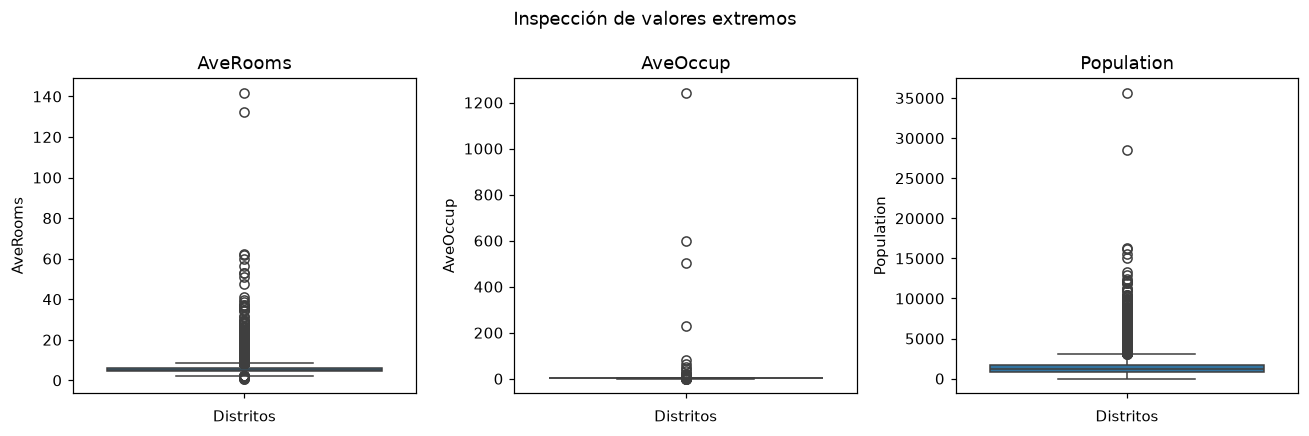

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, columna in zip(axes, ['AveRooms', 'AveOccup', 'Population']):
    sns.boxplot(y=california[columna], ax=ax)
    ax.set(title=columna, xlabel='Distritos', ylabel=columna)
fig.suptitle('Inspección de valores extremos')
plt.tight_layout()
plt.show()

### Ejercicio 12 · Z-score contra IQR

Para **cada columna** de `california`, cuenta cuántos outliers detecta el z-score ($|z| > 3$) y cuántos el IQR. Junta los resultados en un DataFrame con una fila por columna.

**Cómo se resuelve y por qué:** El z-score depende de media y desviación, sensibles a extremos. IQR usa cuartiles y marca valores fuera de Q1−1.5·IQR y Q3+1.5·IQR. Ambos son señales de revisión, no órdenes de borrar.

In [14]:
z = (california - california.mean()) / california.std(ddof=0)
q1 = california.quantile(0.25)
q3 = california.quantile(0.75)
iqr = q3 - q1
fuera_iqr = (california < q1 - 1.5*iqr) | (california > q3 + 1.5*iqr)
conteos_outliers = pd.DataFrame({'z_score': (z.abs() > 3).sum(), 'IQR': fuera_iqr.sum()})
display(conteos_outliers)

             z_score   IQR
MedInc           345   681
HouseAge           0     0
AveRooms         133   511
AveBedrms        145  1424
Population       342  1196
AveOccup           8   711
Latitude           0     0
Longitude          0     0
MedHouseVal        0  1071


✍️ **Pregunta:** en `AveOccup`, ¿por qué el z-score detecta tan pocos outliers y el IQR tantos? ¿Cuál de los dos números te parece más razonable?

**Respuesta explicada:**

En AveOccup, z-score marca 8 y el IQR 711. Los valores enormes inflan la desviación y ocultan otros extremos al z-score. IQR me parece una alerta más útil para revisar la cola, pero no significa que todas esas filas estén equivocadas: la distribución es asimétrica.

### Ejercicio 13 · Criterio de negocio

`AveOccup` es el número medio de personas que viven en cada vivienda del distrito.

a) Muestra los 5 distritos con mayor `AveOccup`.

b) Decide un **umbral razonable** por encima del cual el valor no tiene sentido, y elimina esos distritos. ¿Cuántos eliminaste?

**Cómo se resuelve y por qué:** Usamos un umbral explícito y conservamos el original para poder revisar la decisión. Es un supuesto didáctico que requeriría validación del dominio.

In [15]:
display(california.nlargest(5, 'AveOccup'))
umbral_ocupacion = 20
california_original = california.copy()
california = california.loc[california['AveOccup'] <= umbral_ocupacion].copy()
print('Distritos eliminados:', len(california_original) - len(california))

        MedInc  HouseAge  AveRooms  ...  Latitude  Longitude  MedHouseVal
19006  10.2264      45.0  3.166667  ...     38.32    -121.98        1.375
3364    5.5179      36.0  5.142857  ...     40.41    -120.51        0.675
16669   4.2639      46.0  9.076923  ...     35.32    -120.70        3.500
13034   6.1359      52.0  8.275862  ...     38.69    -121.15        2.250
9172    4.2391       5.0  5.123810  ...     34.47    -118.59        1.546

[5 rows x 9 columns]
Distritos eliminados: 10


✍️ **Pregunta:** ¿qué umbral elegiste y por qué?

**Respuesta explicada:**

Elijo más de 20 ocupantes medios por vivienda y retiro 10 distritos. Una media distrital tan elevada es sospechosa para vivienda convencional, pero no imposible: instalaciones colectivas o denominadores pequeños pueden explicarla. No lo presentaría como regla universal; contrastaría con la fuente antes de eliminar en producción.

### Ejercicio 14 · Winsorización

Winsoriza `AveRooms` en los percentiles 1 y 99, guardando el resultado en una columna nueva `AveRooms_wins`. Compara las estadísticas descriptivas de las dos columnas.

**Cómo se resuelve y por qué:** La winsorización reemplaza extremos por límites percentiles sin eliminar filas. Aquí los percentiles se calculan después del filtro de ocupación y preservamos la columna original.

In [16]:
p01, p99 = california['AveRooms'].quantile([0.01, 0.99])
california['AveRooms_wins'] = california['AveRooms'].clip(lower=p01, upper=p99)
print('Límites:', p01, p99)
display(california[['AveRooms', 'AveRooms_wins']].describe())

Límites: 2.5811006331471136 10.357703818369446
           AveRooms  AveRooms_wins
count  20630.000000   20630.000000
mean       5.428684       5.333831
std        2.474422       1.321309
min        0.846154       2.581101
25%        4.440512       4.440512
50%        5.228973       5.228973
75%        6.052120       6.052120
max      141.909091      10.357704


### Ejercicio 15 · Un caso raro

Muestra los 5 valores más frecuentes de `MedHouseVal`.

**Cómo se resuelve y por qué:** Muchas repeticiones justo en el máximo sugieren un tope de registro, no una observación aislada.

In [17]:
frecuencias_valor = california['MedHouseVal'].value_counts().head(5)
print(frecuencias_valor)
print('En el conjunto original:', california_original['MedHouseVal'].value_counts().head(5))

MedHouseVal
5.00001    964
1.37500    121
1.62500    115
1.12500    103
1.87500     93
Name: count, dtype: int64
En el conjunto original: MedHouseVal
5.00001    965
1.37500    122
1.62500    117
1.12500    103
1.87500     93
Name: count, dtype: int64


✍️ **Pregunta:** ¿qué crees que pasó con el valor más repetido? ¿Es un outlier? ¿Qué problema podría causarle a un modelo que intente predecir el valor de las viviendas?

**Respuesta explicada:**

El valor más repetido es 5.00001, con 964 distritos tras el filtro. El amontonamiento cerca de 5.00001 sugiere un techo de aproximadamente 500000 dólares (la unidad es 100000). Es un patrón de censura o recorte del objetivo, no un error aislado que convenga borrar. El modelo no puede aprender los valores reales por encima del techo y puede subestimar viviendas caras.